<a href="https://colab.research.google.com/github/Xyrfo/PCVK26_24_Rifo/blob/main/Week9_24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODUL 9 - MORFOLOGI CITRA
## Erosi, Dilasi, Opening, Closing, Top-hat, Black-hat, Skeleton, Thinning

**Nama:** Rifo Anggi Barbara Danuarta
**NIM:** 244107020063
**Kelas:** 3F
**No. Absen:** 24


## Persiapan

Citra plat nomor (`plat.jpg`, 4160x3120) di-crop pada area plat lalu diperkecil dengan lebar tetap 520 piksel dan tinggi mengikuti rasio asli, supaya efek structuring element terlihat jelas dan perhitungan manual tetap cepat.

In [3]:
import os
import cv2
import numpy as np
from matplotlib import pyplot as plt

KANDIDAT_FOLDER = [
    os.path.join(os.getcwd(), 'praktikum_foto'),
    r'C:\Teknik Informatika\Semester 5\Citra Digital Dan Visi Komputer\praktikum_foto',
]
PATH = next((p for p in KANDIDAT_FOLDER if os.path.isdir(p)), os.getcwd())
print('Folder citra:', PATH)

EKSTENSI = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

# --- Pengaturan citra plat ---
CROP_PLAT = None        # isi (x, y, w, h) bila auto-crop meleset
LEBAR_PLAT = 520        # lebar hasil (opsi A)
JAGA_RASIO = True       # True: tinggi mengikuti rasio asli; False: paksa 110


def normal(nama):
    akar = os.path.splitext(nama)[0]
    return ''.join(ch for ch in akar.lower() if ch.isalnum())


def cari_file(daftar_nama):
    try:
        isi = [f for f in os.listdir(PATH) if f.lower().endswith(EKSTENSI)]
    except OSError:
        return None
    for target in daftar_nama:
        t = normal(target)
        for f in isi:
            if normal(f) == t:
                return f
    for target in daftar_nama:
        t = normal(target)
        for f in isi:
            n = normal(f)
            if n.startswith(t) or t.startswith(n):
                return f
    return None


F_PLAT = cari_file(['plat.jpg', 'plat nomer.jpg', 'plat nomor.jpg',
                    'plat_nomor.png', 'plat_nomer.jpg', 'plat nomer.jpeg'])
F_NOISE = cari_file(['noisy_text.png', 'noise_text.png', 'noisy_text.jpg',
                     'noise text.png', 'noise_text.jpg'])
F_KITTEN = cari_file(['kitten01 (1).jpg', 'kitten01(1).jpg', 'kitten01.jpg'])
F_LILY = cari_file(['lily.jpg', 'lily.png'])

print()
print('File citra ditemukan:')
print('  plat   :', F_PLAT or '(belum ada)')
print('  noise  :', F_NOISE or '(belum ada)')
print('  kitten :', F_KITTEN or '(belum ada)')
print('  lily   :', F_LILY or '(belum ada)')

Folder citra: /content

File citra ditemukan:
  plat   : plat.jpg
  noise  : noisy_text.png
  kitten : kitten01 (1).jpg
  lily   : lily.jpg


### Crop dan Perkecil Citra Plat

Deteksi area plat memakai Otsu lalu kontur terbesar dengan rasio 2 sampai 6 (bentuk plat nomor).

[Plat] plat.jpg | ukuran asli (3120, 4160)
  Plat terdeteksi: bbox=(351, 744, 3381, 1416) rasio=2.39
  Hasil: crop (1550, 3515) -> (229, 520) | disimpan sebagai plat_proses.png


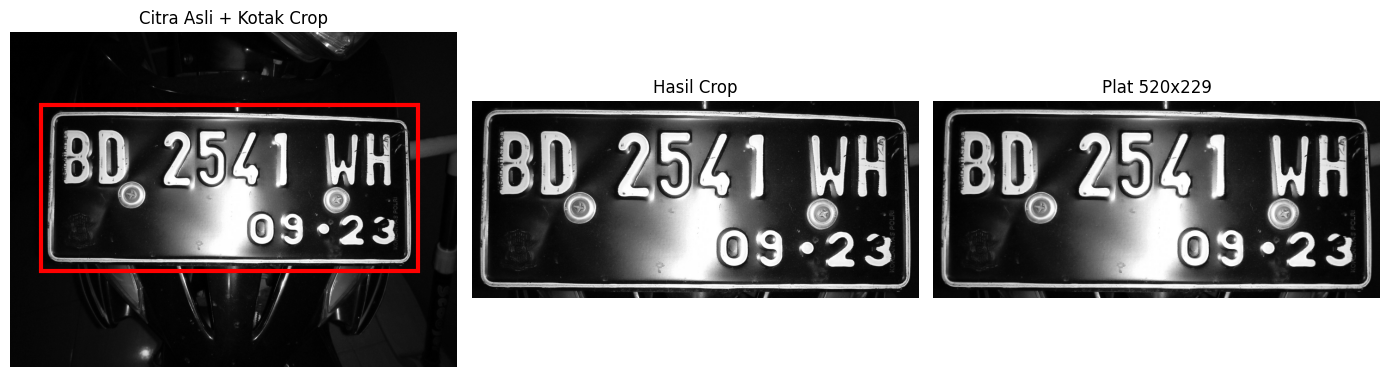

In [4]:
def deteksi_plat(gray):
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, th = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kontur, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    H, W = gray.shape
    kandidat = []
    for c in kontur:
        x, y, w, h = cv2.boundingRect(c)
        if h == 0 or w == 0:
            continue
        rasio = w / float(h)
        if not (2.0 <= rasio <= 6.0):
            continue
        if w * h < 0.05 * H * W:          # terlalu kecil
            continue
        if w < 0.30 * W or h < 0.10 * H:  # terlalu sempit/pendek (refleksi, lampu)
            continue
        if h > 0.70 * H:                  # terlalu tinggi (bukan plat)
            continue
        kandidat.append((w * h, x, y, w, h, rasio))

    if not kandidat:
        return None
    _, x, y, w, h, rasio = max(kandidat)
    print('  Plat terdeteksi: bbox=(%d, %d, %d, %d) rasio=%.2f' % (x, y, w, h, rasio))
    return x, y, w, h


PLAT_SUMBER = cv2.imread(os.path.join(PATH, F_PLAT), cv2.IMREAD_GRAYSCALE) if F_PLAT else None
if PLAT_SUMBER is not None:
    print('[Plat] %s | ukuran asli %s' % (F_PLAT, PLAT_SUMBER.shape))

    if CROP_PLAT is not None:
        x, y, w, h = CROP_PLAT
        print('  Crop manual:', CROP_PLAT)
    else:
        kotak = deteksi_plat(PLAT_SUMBER)
        if kotak is None:
            H, W = PLAT_SUMBER.shape
            x, y, w, h = 0, 0, W, H
            print('  Peringatan: plat tidak terdeteksi, memakai citra utuh.')
        else:
            x, y, w, h = kotak

    H, W = PLAT_SUMBER.shape
    pad = max(2, int(0.02 * w))
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(W, x + w + pad), min(H, y + h + pad)
    potongan = PLAT_SUMBER[y0:y1, x0:x1]

    if JAGA_RASIO:
        tinggi = int(round(LEBAR_PLAT * potongan.shape[0] / float(potongan.shape[1])))
    else:
        tinggi = 110
    plat_proses = cv2.resize(potongan, (LEBAR_PLAT, tinggi), interpolation=cv2.INTER_AREA)

    nama_plat_proses = 'plat_proses.png'
    cv2.imwrite(os.path.join(PATH, nama_plat_proses), plat_proses)
    print('  Hasil: crop %s -> %s | disimpan sebagai %s'
          % (potongan.shape, plat_proses.shape, nama_plat_proses))

    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    ax[0].imshow(PLAT_SUMBER, cmap='gray')
    ax[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0,
                                  edgecolor='red', fill=False, lw=3))
    ax[0].set_title('Citra Asli + Kotak Crop')
    ax[1].imshow(potongan, cmap='gray')
    ax[1].set_title('Hasil Crop')
    ax[2].imshow(plat_proses, cmap='gray')
    ax[2].set_title('Plat %dx%d' % (plat_proses.shape[1], plat_proses.shape[0]))
    for a in ax:
        a.set_axis_off()
    plt.tight_layout()
    plt.show()

    F_PLAT_PAKAI = nama_plat_proses
else:
    F_PLAT_PAKAI = None
    if F_PLAT:
        print('PERINGATAN: citra plat gagal dibaca:', F_PLAT)
    else:
        print('PERINGATAN: citra plat tidak ditemukan di', PATH)

In [5]:
def susun_daftar(label_utama, berkas_utama):
    daftar = []
    if berkas_utama:
        daftar.append(('Output 1 - ' + label_utama, berkas_utama))
    if F_PLAT_PAKAI:
        daftar.append(('Output 2 - Plat Nomor', F_PLAT_PAKAI))
    return daftar


daftar_citra = susun_daftar('Citra Drive', F_NOISE)
daftar_citra_blackhat = susun_daftar('Kitten01', F_KITTEN)
daftar_citra_lily = susun_daftar('Lily', F_LILY)

for nama_daftar, daftar in [('daftar_citra', daftar_citra),
                            ('daftar_citra_blackhat', daftar_citra_blackhat),
                            ('daftar_citra_lily', daftar_citra_lily)]:
    print(nama_daftar, '->', [j for j, _ in daftar] if daftar else 'KOSONG')

if not daftar_citra:
    print('PERINGATAN: tidak ada citra untuk langkah 3-15.')

daftar_citra -> ['Output 1 - Citra Drive', 'Output 2 - Plat Nomor']
daftar_citra_blackhat -> ['Output 1 - Kitten01', 'Output 2 - Plat Nomor']
daftar_citra_lily -> ['Output 1 - Lily', 'Output 2 - Plat Nomor']


## Fungsi Morfologi Manual

Dilasi mengambil nilai **maksimum** pada posisi structuring element (SE) bernilai 1, erosi mengambil nilai **minimum**. Implementasi memakai operasi NumPy per posisi SE (bukan loop per piksel) supaya cepat pada citra besar.

Hanya posisi SE bernilai 1 yang dihitung, sehingga SE cross, garis, dan persegi panjang bekerja benar. Tepi citra dibiarkan 0 seperti pada loop modul.

In [6]:
def _operasi_morfologi(F, SE, jenis):
    F = F.astype(np.uint8)
    p, q = F.shape
    kh, kw = SE.shape
    cy, cx = kh // 2, kw // 2

    P = np.pad(F, ((cy, cy), (cx, cx)), mode='constant', constant_values=0)
    tumpukan = np.stack([P[dy:dy + p, dx:dx + q]
                         for dy in range(kh) for dx in range(kw) if SE[dy, dx]])
    hasil = (tumpukan.max(axis=0) if jenis == 'dilasi'
             else tumpukan.min(axis=0)).astype(np.uint8)

    # samakan dengan modul: piksel tepi tidak diproses (tetap 0)
    if cy:
        hasil[:cy, :] = 0
        hasil[-cy:, :] = 0
    if cx:
        hasil[:, :cx] = 0
        hasil[:, -cx:] = 0
    return hasil


def dilasi_citra(F, SE):
    return _operasi_morfologi(F, SE, 'dilasi')


def erosi_citra(F, SE):
    return _operasi_morfologi(F, SE, 'erosi')


def se_persegi(w):
    return np.ones((w, w), dtype=np.uint8)


def se_cross(w):
    se = np.zeros((w, w), dtype=np.uint8)
    se[w // 2, :] = 1
    se[:, w // 2] = 1
    return se


print('Siap: dilasi_citra(F, SE), erosi_citra(F, SE), se_persegi(w), se_cross(w)')

Siap: dilasi_citra(F, SE), erosi_citra(F, SE), se_persegi(w), se_cross(w)


## Langkah 3 - Dilasi Tanpa Library (SED 5 x 5)

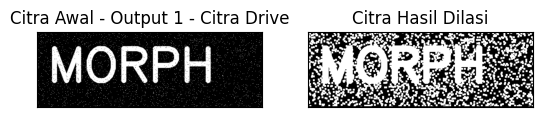

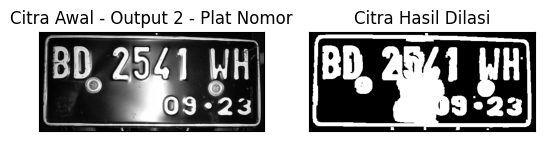

In [7]:
w = 5
for judul, berkas in daftar_citra:
    img_d = cv2.imread(PATH + '/' + berkas, 0)
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    imgD = dilasi_citra(thresh, se_persegi(w))

    plt.figure()
    plt.subplot(121), plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

**Analisis:** Dilasi dengan SED 5x5 memperbesar objek putih. Pada kedua output, huruf dan goresan menjadi lebih tebal serta celah tipis menyempit. Bila bintik noise ikut membesar, itu tanda dilasi memperkuat derau, sehingga ukuran SE harus disesuaikan dengan ketebalan objek.

## Langkah 4 - Dilasi Dengan Library OpenCV (SED 3 x 3)

[[1 1 1]
 [1 1 1]
 [1 1 1]]


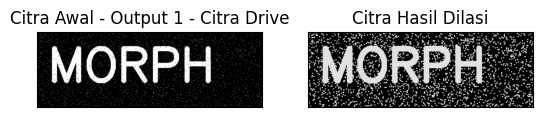

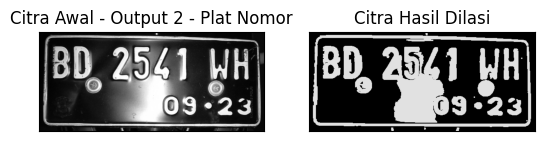

In [8]:
kernel = np.ones((3, 3), np.uint16)
print(kernel)

for judul, berkas in daftar_citra:
    img = cv2.imread(PATH + '/' + berkas)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    dilasi = cv2.dilate(thresh, kernel, iterations=1)

    plt.figure()
    plt.subplot(121), plt.imshow(img)
    plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(dilasi)
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

**Analisis:** Hasil cv2.dilate identik dengan perhitungan manual, hanya berbeda kecepatan karena dijalankan di bahasa C. Citra awal ditampilkan berwarna seperti kode modul, sedangkan hasil dilasi berupa citra biner.

## Langkah 5 - Erosi Tanpa Library (SE 5 x 5)

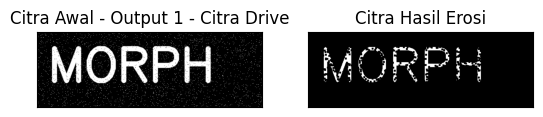

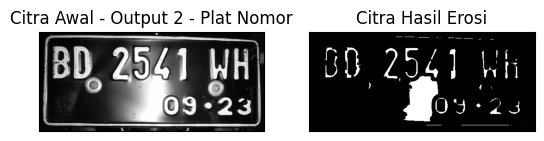

In [9]:
k = 5
for judul, berkas in daftar_citra:
    img_e = cv2.imread(PATH + '/' + berkas, 0)
    ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
    imgE = erosi_citra(thresh1, se_persegi(k))

    plt.figure()
    plt.subplot(121), plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

**Analisis:** Erosi mengikis tepi objek sehingga jumlah piksel putih berkurang. Pada kedua output, huruf menipis dan bagian yang lebih kecil daripada 5x5 hilang. Ambang 175 membuat objek lebih sedikit sehingga efek erosi lebih terlihat dibanding ambang 127.

## Langkah 6 - Erosi Dengan Library OpenCV (SE 5 x 5)

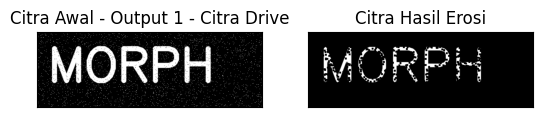

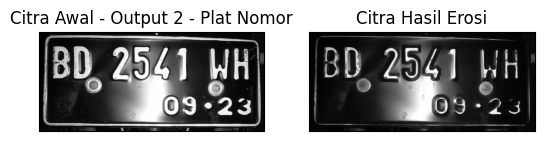

In [10]:
kernel = np.ones((5, 5), np.uint8)

for judul, berkas in daftar_citra:
    img = cv2.imread(PATH + '/' + berkas)
    erosion = cv2.erode(img, kernel, iterations=1)

    plt.figure()
    plt.subplot(121), plt.imshow(img)
    plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(erosion)
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

**Analisis:** cv2.erode menghasilkan citra yang sama dengan erosi manual 5x5. Karena masukan berwarna, erosi diterapkan pada tiap kanal sehingga tepi objek tampak menggelap.

## Langkah 7 - Operasi Opening Tanpa Library Morphology (SE 3 x 3)

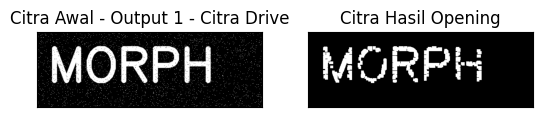

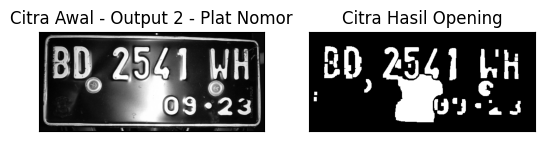

In [11]:
k = 7
for judul, berkas in daftar_citra:
    img_o = cv2.imread(PATH + '/' + berkas, 0)
    reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
    imgO = dilasi_citra(erosi_citra(thresho, se_persegi(k)), se_persegi(k))

    plt.figure()
    plt.subplot(121), plt.imshow(img_o, cmap='gray')
    plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgO, cmap='gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
    plt.show()

**Analisis:** Opening adalah erosi lalu dilasi. Objek kecil dan bintik derau hilang karena erosi, sedangkan objek besar kembali ke ukuran semula setelah dilasi. Sesuai kode modul, SE manual memakai k = 7 sehingga pembersihan lebih kuat daripada versi library 3x3.

## Langkah 8 - Operasi Opening Dengan Library Morphology (SE 3 x 3)

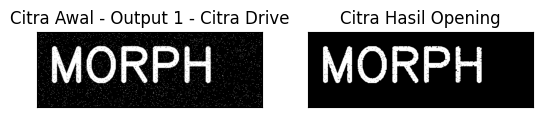

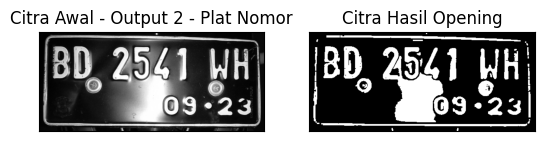

In [12]:
kernel = np.ones((3, 3), np.uint8)

for judul, berkas in daftar_citra:
    img = cv2.imread(PATH + '/' + berkas, 0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

    plt.figure()
    plt.subplot(121), plt.imshow(img, cmap='gray')
    plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(openn, cmap='gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
    plt.show()

**Analisis:** Opening library dengan SE 3x3 hanya menghapus bintik yang lebih kecil daripada 3x3. Karena SE lebih kecil daripada versi manual (k = 7), hasilnya lebih halus dan lebih banyak detail dipertahankan.

## Langkah 9 - Operasi Closing Tanpa Library Morphology (SE 3 x 3)

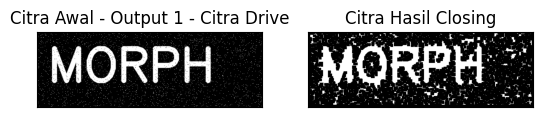

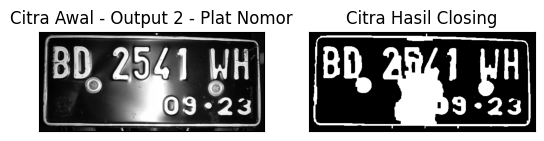

In [13]:
k = 7
for judul, berkas in daftar_citra:
    img_c = cv2.imread(PATH + '/' + berkas, 0)
    retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
    imgC = erosi_citra(dilasi_citra(threshc, se_persegi(k)), se_persegi(k))

    plt.figure()
    plt.subplot(121), plt.imshow(img_c, cmap='gray')
    plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgC, cmap='gray')
    plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
    plt.show()

**Analisis:** Closing adalah dilasi lalu erosi. Celah dan lubang kecil pada objek tertutup sehingga huruf tampak lebih padat. Berbeda dengan opening, objek kecil justru dipertahankan. Perbandingan langkah 7 dan 9 menunjukkan perbedaan tujuan kedua operasi ini.

## Langkah 10 - Operasi Closing Dengan Library Morphology (SE 3 x 3)

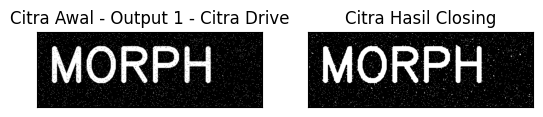

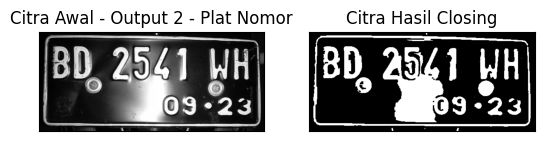

In [14]:
kernel = np.ones((3, 3), np.uint8)

for judul, berkas in daftar_citra:
    img = cv2.imread(PATH + '/' + berkas, 0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    plt.figure()
    plt.subplot(121), plt.imshow(img, cmap='gray')
    plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(closs, cmap='gray')
    plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
    plt.show()

**Analisis:** Closing library dengan SE 3x3 menutup celah tipis saja. Pada plat nomor, lubang kecil di dalam huruf tertutup tanpa mengubah bentuk keseluruhan, sehingga hasil lebih rapi dibanding versi manual k = 7 yang lebih agresif.

## Langkah 11 - Dilasi Structuring Element Cross 3 x 3 dan 5 x 5

SED = Cross 3


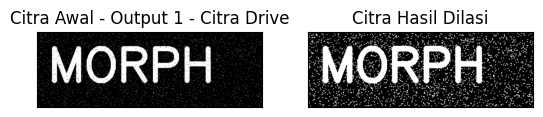

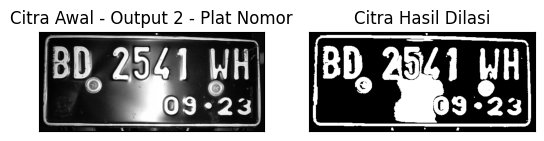

SED = Cross 5


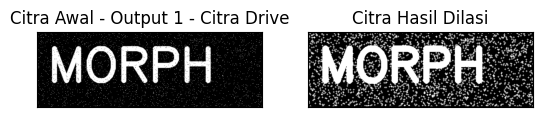

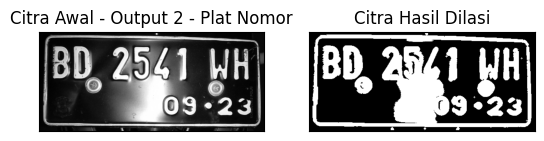

In [15]:
for ukuran in (3, 5):
    print('SED = Cross', ukuran)
    for judul, berkas in daftar_citra:
        img_d = cv2.imread(PATH + '/' + berkas, 0)
        ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
        imgD = dilasi_citra(thresh, se_cross(ukuran))

        plt.figure()
        plt.subplot(121), plt.imshow(img_d, cmap='gray')
        plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
        plt.subplot(122), plt.imshow(imgD, cmap='gray')
        plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
        plt.show()

**Analisis:** Cross 3x3 menebalkan objek ke empat arah langsung, sedangkan cross 5x5 menambah ketebalan sekitar dua piksel ke setiap arah sehingga celah antarhuruf lebih cepat tertutup. Cross tidak menebalkan arah diagonal, sehingga bentuk huruf tetap relatif terjaga.

## Langkah 12 - Dilasi Structuring Element Circular 3 x 3 dan 5 x 5

SED = Circle 3


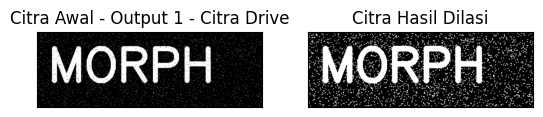

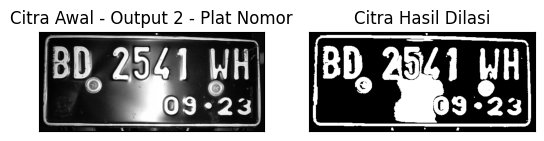

SED = Circle 5


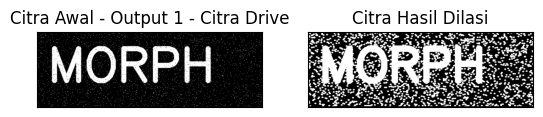

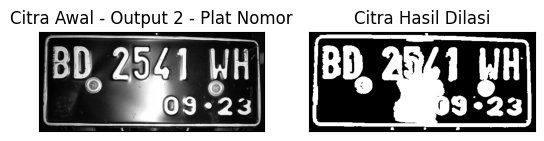

In [16]:
for ukuran in (3, 5):
    print('SED = Circle', ukuran)
    for judul, berkas in daftar_citra:
        img_d = cv2.imread(PATH + '/' + berkas, 0)
        ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
        SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ukuran, ukuran))
        imgD = dilasi_citra(thresh, SE)

        plt.figure()
        plt.subplot(121), plt.imshow(img_d, cmap='gray')
        plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
        plt.subplot(122), plt.imshow(imgD, cmap='gray')
        plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
        plt.show()

**Analisis:** SE circular menebalkan objek merata ke segala arah termasuk diagonal, sehingga hasilnya membulat dan tidak bersudut seperti cross. Circular 5x5 memberi penebalan paling besar. SE bulat dipilih agar distorsi bentuk objek minimum.

## Langkah 13 - Erosi Structuring Element Rectangle 3 x 5 dan 5 x 7

SE = Rectangle 3x5


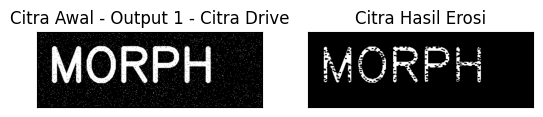

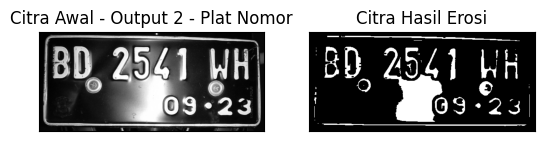

SE = Rectangle 5x7


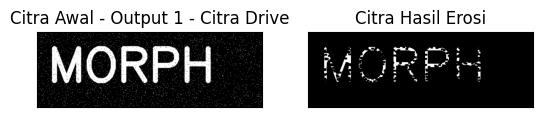

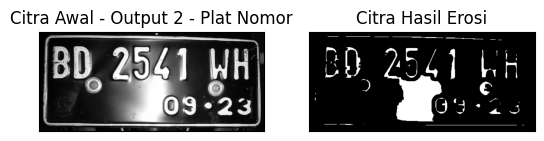

In [17]:
for p, l in ((3, 5), (5, 7)):
    print('SE = Rectangle %dx%d' % (p, l))
    for judul, berkas in daftar_citra:
        img_e = cv2.imread(PATH + '/' + berkas, 0)
        ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
        SE = cv2.getStructuringElement(cv2.MORPH_RECT, (l, p))
        imgE = erosi_citra(thresh1, SE)

        plt.figure()
        plt.subplot(121), plt.imshow(img_e, cmap='gray')
        plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
        plt.subplot(122), plt.imshow(imgE, cmap='gray')
        plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
        plt.show()

**Analisis:** Rectangle 3x5 mengikis lebih banyak ke arah horizontal karena lebarnya lebih besar, sehingga garis tegak menjadi lebih tipis daripada garis datar. Rectangle 5x7 mengikis lebih kuat lagi dan dapat memutus huruf tipis.

## Langkah 14 - Erosi Structuring Element Line Vertikal 3 dan 5

SE = Line Vertikal 3


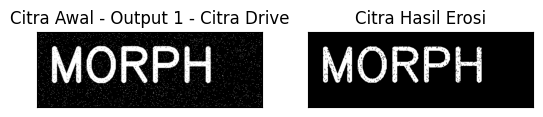

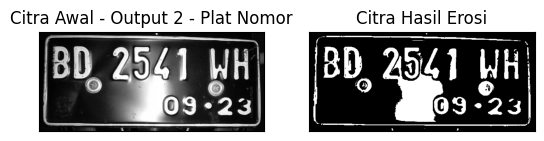

SE = Line Vertikal 5


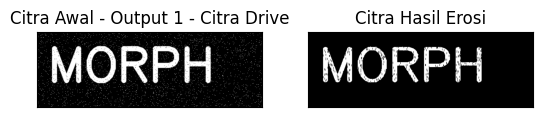

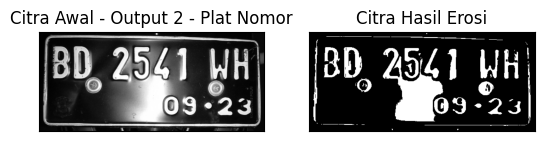

In [18]:
for k in (3, 5):
    print('SE = Line Vertikal', k)
    for judul, berkas in daftar_citra:
        img_e = cv2.imread(PATH + '/' + berkas, 0)
        ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
        SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))
        imgE = erosi_citra(thresh1, SE)

        plt.figure()
        plt.subplot(121), plt.imshow(img_e, cmap='gray')
        plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
        plt.subplot(122), plt.imshow(imgE, cmap='gray')
        plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
        plt.show()

**Analisis:** SE garis vertikal memeriksa satu kolom setinggi k piksel, sehingga goresan tipis arah vertikal cepat hilang sedangkan goresan horizontal relatif bertahan. Line 5 lebih agresif daripada line 3.

## Langkah 15 - Transformasi Top-Hat (SE 3 x 3)

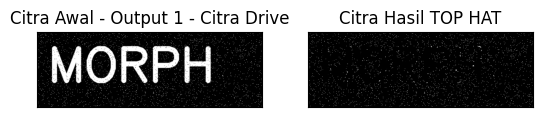

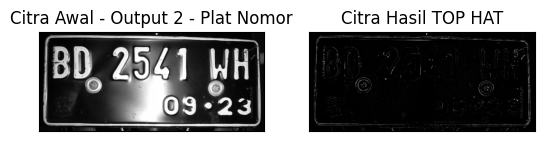

In [19]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

for judul, berkas in daftar_citra:
    img = cv2.imread(PATH + '/' + berkas)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

    plt.figure()
    plt.subplot(121), plt.imshow(img, cmap='gray')
    plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(tophat_img, cmap='gray')
    plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
    plt.show()

**Analisis:** Top-hat adalah citra asli dikurangi hasil opening, sehingga menyisakan fitur terang yang lebih kecil daripada SE. Bidang terang besar menjadi hitam, sedangkan detail terang kecil tetap tampak. Operator ini berguna untuk meratakan pencahayaan latar sebelum thresholding.

## Langkah 16 - Transformasi Black-Hat (SE 13 x 5)

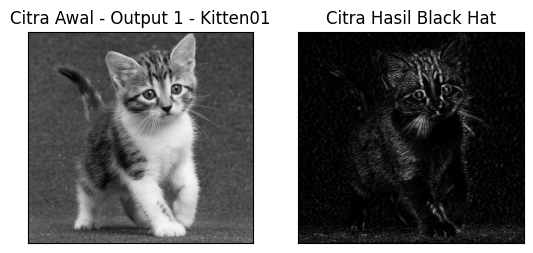

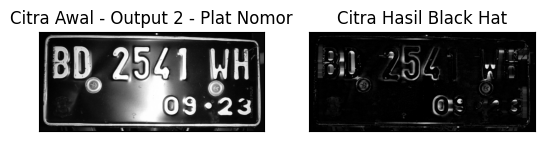

In [20]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

for judul, berkas in daftar_citra_blackhat:
    img = cv2.imread(PATH + '/' + berkas)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
    blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

    plt.figure()
    plt.subplot(121), plt.imshow(img, cmap='gray')
    plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(blackhat, cmap='gray')
    plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
    plt.show()

**Analisis:** Black-hat adalah hasil closing dikurangi citra asli, sehingga menyisakan fitur gelap yang lebih kecil daripada SE. Sesuai kode modul, langkah ini memakai citra kitten dan kernel 13x5 yang lebar, sehingga fitur gelap memanjang arah horizontal lebih ditonjolkan. Arah pengurangan harus closing dikurangi asli; bila dibalik hasilnya nol.

## Langkah 17 - Skeleton Pada Citra Biner

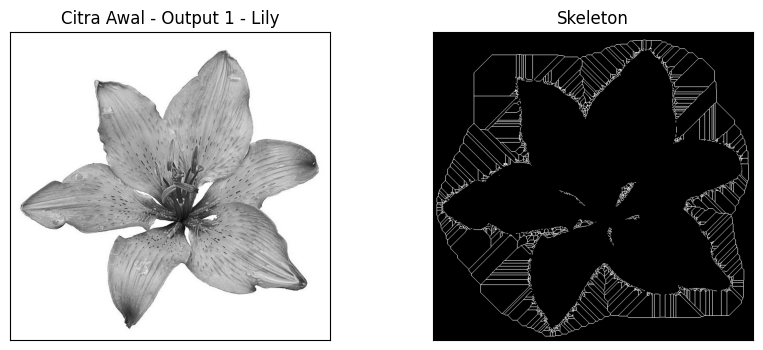

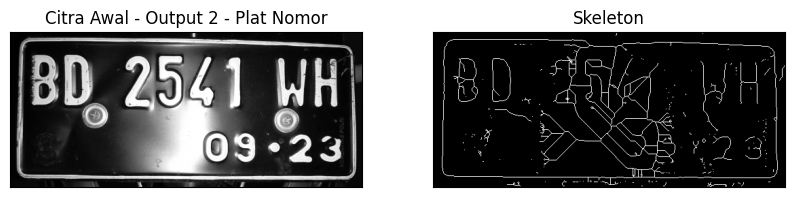

In [21]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

for judul, berkas in daftar_citra_lily:
    img = cv.imread(PATH + '/' + berkas, 0)
    binary = img > filters.threshold_triangle(img)

    binary_cp = binary.copy()
    binary_cp[binary_cp == True] = 1
    binary_cp[binary_cp == False] = 0

    skeleton = skeletonize(binary_cp)

    plt.figure(figsize=(10, 4))
    plt.subplot(121), plt.imshow(img, cmap='gray')
    plt.title('Citra Awal - ' + judul), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(skeleton, cmap='gray')
    plt.title('Skeleton'), plt.xticks([]), plt.yticks([])
    plt.show()

**Analisis:** Skeleton mereduksi objek menjadi rangka setebal satu piksel namun mempertahankan arah dan percabangan. Pada lily rangka mengikuti struktur batang, sedangkan pada plat nomor rangka mengikuti huruf. Pemilihan tanda pembanding menentukan bagian mana yang dianggap objek.

## Langkah 18 - Skeleton Pada Citra Hasil Inversi

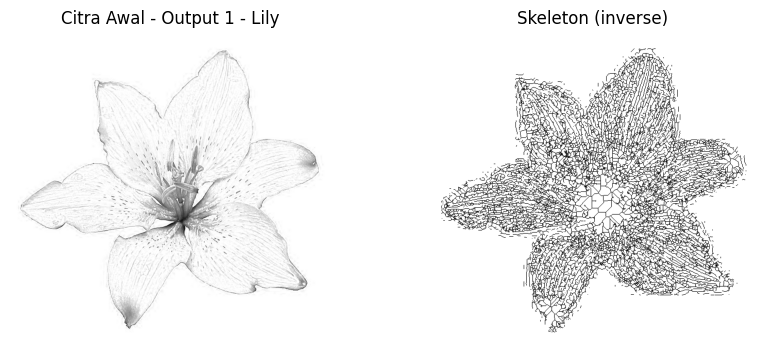

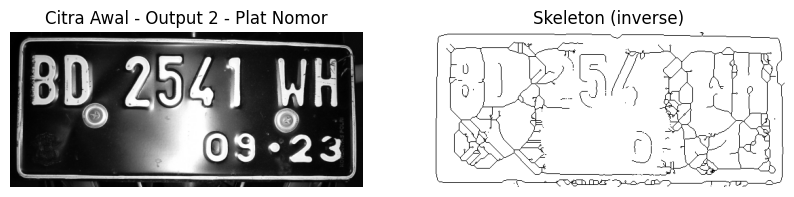

In [22]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

for judul, berkas in daftar_citra_lily:
    arr = io.imread(PATH + '/' + berkas)
    img = arr if arr.ndim == 2 else arr[..., 0]
    binary = img < filters.threshold_triangle(img)
    skeleton = skeletonize(binary)

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(img, cmap='gray')
    ax[0].set_title('Citra Awal - ' + judul)
    ax[0].set_axis_off()
    ax[1].imshow(skeleton, cmap='gray_r')
    ax[1].set_title('Skeleton (inverse)')
    ax[1].set_axis_off()
    plt.show()

**Analisis:** Dengan pembanding dibalik, objek yang dirangkai adalah bagian gelap. Hasilnya berbeda dari langkah 17 dan umumnya menutupi area latar. Colormap gray_r dipakai agar rangka terlihat gelap di atas latar terang. Ini menunjukkan bahwa skeleton sangat bergantung pada definisi objek pada citra biner.

## Langkah 19 - Thinning dan Perbandingan Dengan Skeleton

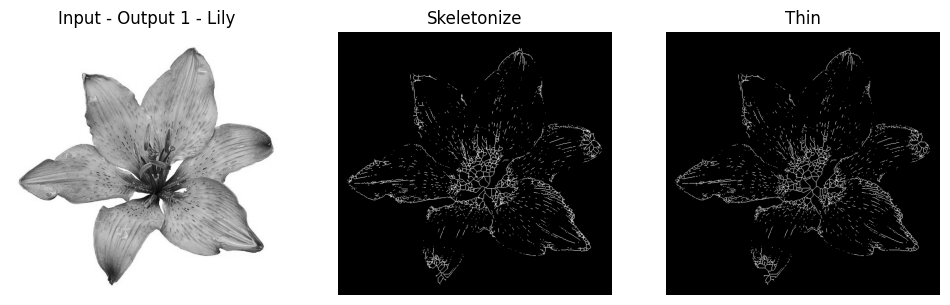

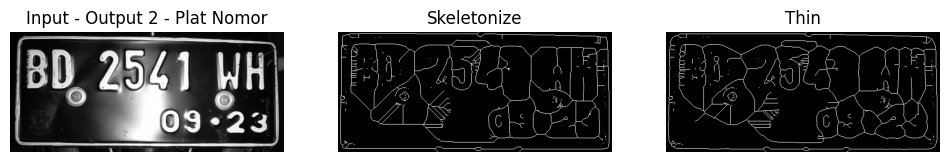

In [23]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

for judul, berkas in daftar_citra_lily:
    arr = io.imread(PATH + '/' + berkas)
    if arr.ndim == 2:
        image = img_as_float(arr)
    else:
        image = img_as_float(color.rgb2gray(arr[..., :3]))
    image_binary = image < 0.5
    out_skeletonize = morphology.skeletonize(image_binary)
    out_thin = morphology.thin(image_binary)

    f, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(12, 4))
    ax0.imshow(image, cmap='gray')
    ax0.set_title('Input - ' + judul)
    ax1.imshow(out_skeletonize, cmap='gray')
    ax1.set_title('Skeletonize')
    ax2.imshow(out_thin, cmap='gray')
    ax2.set_title('Thin')
    for ax in (ax0, ax1, ax2):
        ax.set_axis_off()
    plt.show()

**Analisis:** Skeletonize dan thin sama-sama menipiskan objek menjadi rangka, tetapi algoritmanya berbeda sehingga jumlah piksel hasilnya tidak selalu sama. Thin menghapus piksel secara berulang berdasarkan pola tetangga, sedangkan skeletonize memakai transformasi morfologi yang menjamin rangka setebal satu piksel. Perbedaan paling terasa pada ujung dan percabangan objek.

## Ringkasan

| Langkah | Operasi | SE / parameter |
|---|---|---|
| 3 | Dilasi manual | persegi 5x5 |
| 4 | Dilasi library | 3x3 |
| 5 | Erosi manual | persegi 5x5 |
| 6 | Erosi library | 5x5 |
| 7 | Opening manual | k = 7 |
| 8 | Opening library | 3x3 |
| 9 | Closing manual | k = 7 |
| 10 | Closing library | 3x3 |
| 11 | Dilasi cross | 3x3 dan 5x5 |
| 12 | Dilasi circular | 3x3 dan 5x5 |
| 13 | Erosi rectangle | 3x5 dan 5x7 |
| 14 | Erosi line vertikal | 3 dan 5 |
| 15 | Top-hat | 3x3 |
| 16 | Black-hat | 13x5 |
| 17 | Skeleton biner | threshold_triangle |
| 18 | Skeleton inversi | pembanding dibalik |
| 19 | Thinning | morphology.thin |



## Kesimpulan

Seluruh operasi turunan morfologi dibangun dari erosi dan dilasi. Opening adalah erosi lalu dilasi untuk menghapus objek kecil, closing adalah dilasi lalu erosi untuk menutup celah, sedangkan top-hat dan black-hat adalah selisih antara citra asli dan hasil opening atau closing.

Ukuran dan bentuk structuring element menentukan hasil. SE 3x3 cukup untuk noise halus, SE 5x5 atau lebih besar diperlukan untuk menutup celah lebar dengan risiko menyatukan objek yang seharusnya terpisah. SE cross dan circular menebalkan merata, sedangkan SE line dan rectangle memberi efek berarah.

Dengan menjalankan setiap langkah pada dua citra, pengaruh parameter yang sama dapat dibandingkan langsung pada objek berbeda: citra dari folder praktikum mewakili kasus modul, sedangkan plat nomor mewakili kasus nyata dengan huruf tebal dan latar kontras tinggi.